In [1]:
try:
    import pandas as pd
    import numpy as np
    import statistics
    import math
    print('Libraries has been successfuly installed')
except ImportError:
    print('Library not found : check installation')

Libraries has been successfuly installed


In [2]:
df = pd.read_csv(r"C:\Users\Youss\Documents\IAOADA201\apronfodir les systems decisionelles\seance 10 - synthese\data\commandes.csv")
df

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client
0,CMD0001,2025-01-01,Casablanca,Femme,44.0,Beauté,Application,3.0,210.97,A,2.0,Non,Moyen,Non
1,CMD0002,2025-01-01,Tétouan,Femme,26.0,Mode,Web,5.0,579.45,B,5.0,Non,Faible,Non
2,CMD0003,2025-01-03,Tanger,Homme,28.0,Sport,Application,2.0,372.35,B,2.0,Non,elevé,Non
3,CMD0004,2025-01-05,Rabat,Femme,18.0,Mode,Application,3.0,478.11,C,4.0,Oui,Faible,Oui
4,CMD0005,2025-01-05,Rabat,Femme,41.0,Électronique,Application,7.0,411.04,C,4.0,Non,Élevé,Non
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
513,CMD0497,2025-12-30,Tétouan,Homme,42.0,Beauté,Web,2.0,56.07,B,4.0,Non,Faible,Non
514,CMD0498,2025-12-30,Rabat,Femme,18.0,Électronique,Web,1.0,693.66,A,4.0,Non,Faible,Non
515,CMD0498,2025-12-30,Rabat,Femme,18.0,Électronique,Web,1.0,693.66,A,4.0,Non,Faible,Non
516,CMD0499,30/12/2025,Casablanca,Homme,41.0,Mode,Web,3.0,443.36,A,4.0,Non,Moyen,Non


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 518 entries, 0 to 517
Data columns (total 14 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_commande            518 non-null    str    
 1   date_commande          518 non-null    str    
 2   ville                  518 non-null    str    
 3   sexe                   508 non-null    str    
 4   age_client             495 non-null    float64
 5   categorie              518 non-null    str    
 6   canal                  510 non-null    str    
 7   nb_articles            512 non-null    float64
 8   montant_dh             503 non-null    float64
 9   entrepot               518 non-null    str    
 10  delai_livraison_jours  500 non-null    float64
 11  colis_endommage        518 non-null    str    
 12  satisfaction           475 non-null    str    
 13  retour_client          518 non-null    str    
dtypes: float64(4), str(10)
memory usage: 56.8 KB


In [4]:
df.columns = df.columns.str.strip().str.lower()

In [5]:
df['ville'] = df['ville'].str.strip().str.lower().str.replace("é", "e").str.replace("è","e")
df['ville'].unique()

<StringArray>
['casablanca', 'tetouan', 'tanger', 'rabat', 'fes', 'agadir', 'marrakech']
Length: 7, dtype: str

In [6]:
df['sexe'] = df['sexe'].str.strip().str.lower()

df['sexe'].unique()


<StringArray>
['femme', 'homme', nan]
Length: 3, dtype: str

In [7]:
df['categorie'] = df['categorie'].str.strip().str.lower().str.replace("é", "e").str.replace("è","e")
df['categorie'].unique()

<StringArray>
['beaute', 'mode', 'sport', 'electronique', 'maison']
Length: 5, dtype: str

In [8]:
df['satisfaction'] = df['satisfaction'].str.strip().str.lower().str.replace("é", "e").str.replace("è","e")
df['satisfaction'].unique()

<StringArray>
['moyen', 'faible', 'eleve', nan]
Length: 4, dtype: str

In [9]:
df['canal'] = df['canal'].str.strip().str.lower().str.replace("é", "e")
df['canal'].unique()

<StringArray>
['application', 'web', 'telephone', nan]
Length: 4, dtype: str

In [10]:
df['retour_client'] = df['retour_client'].str.strip().str.lower()
df['retour_client'].unique()

<StringArray>
['non', 'oui']
Length: 2, dtype: str

In [11]:
df['date_commande'] = pd.to_datetime(df['date_commande'], format="mixed")

df['mois'] = df['date_commande'].dt.month

In [12]:
doublons = df.duplicated(subset="id_commande").sum()

df_v2 = df.drop_duplicates()

print(f"shape of new dataset is : {df_v2.shape}")

shape of new dataset is : (500, 15)


In [13]:
df_v2.isnull().sum()

id_commande               0
date_commande             0
ville                     0
sexe                     10
age_client               22
categorie                 0
canal                     8
nb_articles               6
montant_dh               15
entrepot                  0
delai_livraison_jours    18
colis_endommage           0
satisfaction             40
retour_client             0
mois                      0
dtype: int64

In [14]:
df_v2['sexe'] = df_v2["sexe"].fillna("unkown")

df_v2['age_client'] = df_v2['age_client'].fillna(df_v2['age_client'].median())

df_v2['montant_dh'] = df_v2['montant_dh'].fillna(df_v2['montant_dh'].median())

df_v2['delai_livraison_jours'] = df_v2['delai_livraison_jours'].fillna(df_v2['delai_livraison_jours'].median())

df_v2['canal'] = df_v2['canal'].fillna(df_v2['canal'].mode()[0])

df_v2['satisfaction'] = df_v2['satisfaction'].fillna("unkown")

df_v2['nb_articles'] = df_v2['nb_articles'].fillna(df_v2['nb_articles'].median())



In [18]:
#checking the missing values
df_v2.isnull().sum()

id_commande              0
date_commande            0
ville                    0
sexe                     0
age_client               0
categorie                0
canal                    0
nb_articles              0
montant_dh               0
entrepot                 0
delai_livraison_jours    0
colis_endommage          0
satisfaction             0
retour_client            0
mois                     0
dtype: int64

In [16]:
data = df_v2.copy()
data

,id_commande,date_commande,ville,sexe,age_client,categorie,canal,nb_articles,montant_dh,entrepot,delai_livraison_jours,colis_endommage,satisfaction,retour_client,mois
0,CMD0001,2025-01-01,casablanca,femme,44.0,beaute,application,3.0,210.97,A,2.0,Non,moyen,non,1
1,CMD0002,2025-01-01,tetouan,femme,26.0,mode,web,5.0,579.45,B,5.0,Non,faible,non,1
2,CMD0003,2025-01-03,tanger,homme,28.0,sport,application,2.0,372.35,B,2.0,Non,eleve,non,1
3,CMD0004,2025-01-05,rabat,femme,18.0,mode,application,3.0,478.11,C,4.0,Oui,faible,oui,1
4,CMD0005,2025-01-05,rabat,femme,41.0,electronique,application,7.0,411.04,C,4.0,Non,eleve,non,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
512,CMD0496,2025-12-30,fes,femme,55.0,maison,web,1.0,469.10,B,2.0,Non,eleve,non,12
513,CMD0497,2025-12-30,tetouan,homme,42.0,beaute,web,2.0,56.07,B,4.0,Non,faible,non,12
514,CMD0498,2025-12-30,rabat,femme,18.0,electronique,web,1.0,693.66,A,4.0,Non,faible,non,12
516,CMD0499,2025-12-30,casablanca,homme,41.0,mode,web,3.0,443.36,A,4.0,Non,moyen,non,12


### Mesure centrales

In [19]:
"""calcul des mesures centrales"""
vars =  [data['age_client'], data['nb_articles'], data['montant_dh'], data['delai_livraison_jours']]

for x in vars:
        print(f"\n{x.name}  : moyenne = {statistics.mean(x)}, median = {statistics.median(x)}, mode = {statistics.mode(x)} ")


age_client  : moyenne = 34.944, median = 35.0, mode = 35.0 

nb_articles  : moyenne = 2.516, median = 2.0, mode = 1.0 

montant_dh  : moyenne = 701.02728, median = 385.87, mode = 385.87 

delai_livraison_jours  : moyenne = 3.518, median = 3.0, mode = 3.0 


In [23]:
catg = [data['satisfaction'],data['canal'],data['categorie'],data['ville'] ]

for i in catg:
    print(f"\n{i.name}  : mode = {statistics.mode(i)}")


satisfaction  : mode = moyen

canal  : mode = web

categorie  : mode = mode

ville  : mode = casablanca


In [27]:
montant_mesures = data.groupby('categorie')['montant_dh'].agg(['mean','median'])
montant_mesures

,mean,median
categorie,,
beaute,486.666136,193.460
electronique,1119.087549,1041.190
maison,1040.346211,474.430
mode,470.493525,311.700
sport,385.639474,379.575


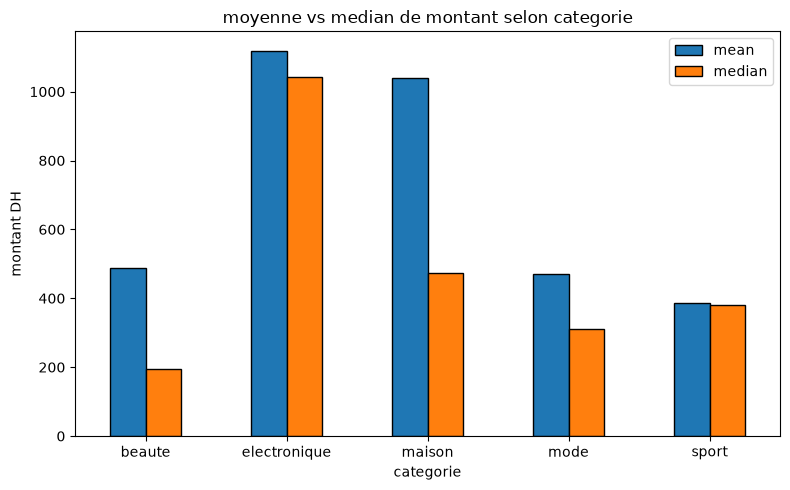

In [30]:
from matplotlib import pyplot as plt

fig, ax = plt.subplots(figsize=(8,5))

montant_mesures.plot(kind='bar', ax=ax, edgecolor='black')

ax.set_title("moyenne vs median de montant selon categorie")
ax.set_xlabel("categorie")
ax.set_ylabel("montant DH")
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()

plt.show()

## mesure de disperssion

In [31]:
data.describe()

,date_commande,age_client,nb_articles,montant_dh,delai_livraison_jours,mois
count,500,500.000000,500.000000,500.000000,500.000000,500.000000
mean,2025-07-02 15:07:12,34.944000,2.516000,701.027280,3.518000,6.550000
min,2025-01-01 00:00:00,0.000000,0.000000,-150.000000,-2.000000,1.000000
25%,2025-04-01 18:00:00,27.000000,1.000000,266.042500,2.000000,4.000000
50%,2025-07-04 00:00:00,35.000000,2.000000,385.870000,3.000000,7.000000
75%,2025-09-29 00:00:00,42.000000,3.000000,609.747500,4.000000,9.000000
max,2025-12-30 00:00:00,130.000000,40.000000,32000.000000,60.000000,12.000000
std,NaN,11.425846,2.605248,2194.759278,3.765905,3.422122


In [32]:
montant = data['montant_dh']
age_client = data['age_client']
delai = data['delai_livraison_jours']

In [35]:
# montant 
print(f"\nMontant_DH : etendue = {round(max(montant)-min(montant),2)}, variance = {round(statistics.variance(montant),2)}, ecart-type = {round(np.std(montant),2)}")

#age client
print(f"\nAge client : etendue = {round(max(age_client)-min(age_client),1)}, variance = {round(statistics.variance(age_client),2)}, ecart-type = {round(np.std(age_client),2)}")

#delai
print(f"\nDelai : etendue = {max(delai)-min(delai)}, variance = {round(statistics.variance(delai),2)}, ecart-type = {round(np.std(delai),2)}")


Montant_DH : etendue = 32150.0, variance = 4816968.29, ecart-type = 2192.56

Age client : etendue = 130.0, variance = 130.55, ecart-type = 11.41

Delai : etendue = 62.0, variance = 14.18, ecart-type = 3.76


In [37]:
delai_std_ville = round(data.groupby('ville')["delai_livraison_jours"].std(),2)
delai_std_ville

ville
agadir        1.27
casablanca    4.01
fes           1.21
marrakech     1.14
rabat         3.96
tanger        6.59
tetouan       1.20
Name: delai_livraison_jours, dtype: float64

In [40]:
top5 = data['montant_dh'].nlargest(5)
print(top5)

df_v3 = data.drop(index=top5.index)
print(df_v3.shape)

110    32000.00
392    25000.00
409    21000.00
211    18500.00
334     2892.47
Name: montant_dh, dtype: float64
(495, 15)


In [41]:
montant_v3 = df_v3['montant_dh']

print(f"\nMontant_DH : etendue = {round(max(montant_v3)-min(montant_v3),2)}, variance = {round(statistics.variance(montant_v3),2)}, ecart-type = {round(np.std(montant_v3),2)}")



Montant_DH : etendue = 2626.34, variance = 164722.18, ecart-type = 405.45


In [49]:
#taux de changement de l'ecart type apres supression des valeurs extremes

std_avant = data['montant_dh'].std()
std_apres = df_v3['montant_dh'].std()

std_var = std_apres-std_avant
prc_var = (std_apres-std_avant) / std_avant * 100

print(f"avant : {std_avant:.2f} DH")
print(f"\napres : {std_apres:.2f} DH")

print(f"\nValeur de changement de montant : {std_var:.2f} DH")
print(f"\nTaux de changement de montant : {prc_var:.2f}%")

avant : 2194.76 DH

apres : 405.86 DH

Valeur de changement de montant : -1788.90 DH

Taux de changement de montant : -81.51%


In [51]:
print("---le coefficient de variance---")
coef_var = std_avant/montant.mean()
print(f"\ncoefficient de variance = {coef_var:.2f}")

---le coefficient de variance---

coefficient de variance = 3.13
